# NOTEBOOK : 02_data_exploration.ipynb
# ROLE     : Explore match & auxiliary datasets, check consistency, spot team name mismatches, compute baselines, and save figures.
# INPUT    : ../../data/processed/all_matches_raw.csv + ../../data/raw/<season>/*.csv
# OUTPUT   : ../reports/figures/*.png and ../reports/exploration_summary.txt

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 42
RAW_DATA_DIR = Path("../../data/raw")
INPUT_FILE = Path("../../data/processed/all_matches_raw.csv")
FIGURES_DIR = Path("../reports/figures")
SUMMARY_FILE = Path("../reports/exploration_summary.txt")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SAMPLE_SEASON = "2020-21"

CORE_MATCH_COLS = [
    "season", "Match_Date", "Home_Team", "Away_Team",
    "Full_Time_Home_Goals", "Full_Time_Away_Goals", "Full_Time_Result",
    "Home_Shots", "Away_Shots", "Home_Shots_On_Target", "Away_Shots_On_Target",
    "Home_Corners", "Away_Corners", "Home_Yellow_Cards", "Away_Yellow_Cards",
    "Home_Red_Cards", "Away_Red_Cards",
]

print("Configuration loaded.")

Configuration loaded.


In [2]:
df = pd.read_csv(INPUT_FILE)

print("Shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("\nCore columns missing values:")
print(df[CORE_MATCH_COLS].isna().sum())

print("\nCore columns dtypes:")
print(df[CORE_MATCH_COLS].dtypes)

display(df[CORE_MATCH_COLS].head())
display(df[CORE_MATCH_COLS].describe())

Shape: (2350, 177)
Duplicate rows: 0

Core columns missing values:
season                  0
Match_Date              0
Home_Team               0
Away_Team               0
Full_Time_Home_Goals    0
Full_Time_Away_Goals    0
Full_Time_Result        0
Home_Shots              0
Away_Shots              0
Home_Shots_On_Target    0
Away_Shots_On_Target    0
Home_Corners            0
Away_Corners            0
Home_Yellow_Cards       0
Away_Yellow_Cards       0
Home_Red_Cards          0
Away_Red_Cards          0
dtype: int64

Core columns dtypes:
season                    str
Match_Date                str
Home_Team                 str
Away_Team                 str
Full_Time_Home_Goals    int64
Full_Time_Away_Goals    int64
Full_Time_Result          str
Home_Shots              int64
Away_Shots              int64
Home_Shots_On_Target    int64
Away_Shots_On_Target    int64
Home_Corners            int64
Away_Corners            int64
Home_Yellow_Cards       int64
Away_Yellow_Cards       int64
Home_R

,season,Match_Date,Home_Team,Away_Team,Full_Time_Home_Goals,Full_Time_Away_Goals,Full_Time_Result,Home_Shots,Away_Shots,Home_Shots_On_Target,Away_Shots_On_Target,Home_Corners,Away_Corners,Home_Yellow_Cards,Away_Yellow_Cards,Home_Red_Cards,Away_Red_Cards
0,2020-21,12/09/2020,Fulham,Arsenal,0,3,A,5,13,2,6,2,3,2,2,0,0
1,2020-21,12/09/2020,Crystal Palace,Southampton,1,0,H,5,9,3,5,7,3,2,1,0,0
2,2020-21,12/09/2020,Liverpool,Leeds,4,3,H,22,6,6,3,9,0,1,0,0,0
3,2020-21,12/09/2020,West Ham,Newcastle,0,2,A,15,15,3,2,8,7,2,2,0,0
4,2020-21,13/09/2020,West Brom,Leicester,0,3,A,7,13,1,7,2,5,1,1,0,0


,Full_Time_Home_Goals,Full_Time_Away_Goals,Home_Shots,Away_Shots,Home_Shots_On_Target,Away_Shots_On_Target,Home_Corners,Away_Corners,Home_Yellow_Cards,Away_Yellow_Cards,Home_Red_Cards,Away_Red_Cards
count,2350.000000,2350.000000,2350.000000,2350.000000,2350.000000,2350.000000,2350.000000,2350.000000,2350.000000,2350.000000,2350.000000,2350.000000
mean,1.558298,1.330213,13.955319,11.689362,4.815319,4.111064,5.598723,4.682553,1.708511,1.939574,0.057021,0.061277
std,1.324606,1.209399,5.635679,5.135094,2.563111,2.348701,3.040145,2.810700,1.290059,1.343103,0.244444,0.246885
min,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,0.000000,10.000000,8.000000,3.000000,2.000000,3.000000,3.000000,1.000000,1.000000,0.000000,0.000000
50%,1.000000,1.000000,13.000000,11.000000,5.000000,4.000000,5.000000,4.000000,2.000000,2.000000,0.000000,0.000000
75%,2.000000,2.000000,17.000000,15.000000,6.000000,5.000000,7.000000,6.000000,2.000000,3.000000,0.000000,0.000000
max,9.000000,8.000000,36.000000,37.000000,16.000000,15.000000,17.000000,19.000000,7.000000,8.000000,2.000000,2.000000


In [3]:
aux_files = [
    "master_gameweeks.csv",
    "master_player_gw.csv",
    "master_player_history.csv",
    "master_understat_teams.csv",
    "master_xP_projections.csv",
]

sample_dir = RAW_DATA_DIR / SAMPLE_SEASON
for filename in aux_files:
    file_path = sample_dir / filename
    if file_path.exists():
        aux_df = pd.read_csv(file_path)
        print(f"--- {filename} ({SAMPLE_SEASON}) ---")
        print(f"Shape: {aux_df.shape}")
        print(f"Columns: {list(aux_df.columns)}\n")
    else:
        print(f"[MISSING] {filename} not found in {sample_dir}\n")

--- master_gameweeks.csv (2020-21) ---
Shape: (24365, 35)
Columns: ['name', 'position', 'team', 'xP', 'assists', 'bonus', 'bps', 'clean_sheets', 'creativity', 'element', 'fixture', 'goals_conceded', 'goals_scored', 'ict_index', 'influence', 'kickoff_time', 'minutes', 'opponent_team', 'own_goals', 'penalties_missed', 'penalties_saved', 'red_cards', 'round', 'saves', 'selected', 'team_a_score', 'team_h_score', 'threat', 'total_points', 'transfers_balance', 'transfers_in', 'transfers_out', 'value', 'was_home', 'yellow_cards']

--- master_player_gw.csv (2020-21) ---
Shape: (24365, 32)
Columns: ['assists', 'bonus', 'bps', 'clean_sheets', 'creativity', 'element', 'fixture', 'goals_conceded', 'goals_scored', 'ict_index', 'influence', 'kickoff_time', 'minutes', 'opponent_team', 'own_goals', 'penalties_missed', 'penalties_saved', 'red_cards', 'round', 'saves', 'selected', 'team_a_score', 'team_h_score', 'threat', 'total_points', 'transfers_balance', 'transfers_in', 'transfers_out', 'value', 'wa

In [4]:
print("Matches per season:")
for season, group in df.groupby("season"):
    played = group["Full_Time_Result"].notna().sum()
    upcoming = group["Full_Time_Result"].isna().sum()
    print(f"  {season}: total={len(group)} | played={played} | upcoming={upcoming}")

Matches per season:
  2020-21: total=380 | played=380 | upcoming=0
  2021-22: total=380 | played=380 | upcoming=0
  2022-23: total=380 | played=380 | upcoming=0
  2023-24: total=380 | played=380 | upcoming=0
  2024-25: total=380 | played=380 | upcoming=0
  2025-26: total=380 | played=380 | upcoming=0
  2026-27: total=70 | played=70 | upcoming=0


In [5]:
match_teams = sorted(set(df["Home_Team"].dropna().unique()) | set(df["Away_Team"].dropna().unique()))
print(f"Unique teams in Match CSVs ({len(match_teams)}):")
print(match_teams)

# Compare with master_gameweeks.csv and master_understat_teams.csv from sample season
gw_df = pd.read_csv(sample_dir / "master_gameweeks.csv")
gw_teams = sorted(gw_df["team"].dropna().unique())
print(f"\nTeams in master_gameweeks.csv ({SAMPLE_SEASON}):")
print(gw_teams)

understat_path = sample_dir / "master_understat_teams.csv"
if understat_path.exists():
    us_df = pd.read_csv(understat_path)
    us_teams = sorted(us_df["team_name"].dropna().unique())
    print(f"\nTeams in master_understat_teams.csv ({SAMPLE_SEASON}):")
    print(us_teams)

print("\nTeams in gameweeks NOT matching Match CSV names:")
print(sorted(set(gw_teams) - set(match_teams)))

Unique teams in Match CSVs (30):
['Arsenal', 'Aston Villa', 'Bournemouth', 'Brentford', 'Brighton', 'Burnley', 'Chelsea', 'Coventry', 'Crystal Palace', 'Everton', 'Fulham', 'Hull', 'Ipswich', 'Leeds', 'Leicester', 'Liverpool', 'Luton', 'Man City', 'Man United', 'Newcastle', 'Norwich', "Nott'm Forest", 'Sheffield United', 'Southampton', 'Sunderland', 'Tottenham', 'Watford', 'West Brom', 'West Ham', 'Wolves']

Teams in master_gameweeks.csv (2020-21):
['Arsenal', 'Aston Villa', 'Brighton', 'Burnley', 'Chelsea', 'Crystal Palace', 'Everton', 'Fulham', 'Leeds', 'Leicester', 'Liverpool', 'Man City', 'Man Utd', 'Newcastle', 'Sheffield Utd', 'Southampton', 'Spurs', 'West Brom', 'West Ham', 'Wolves']

Teams in master_understat_teams.csv (2020-21):
['Arsenal', 'Aston_Villa', 'Bournemouth', 'Brighton', 'Burnley', 'Chelsea', 'Crystal_Palace', 'Everton', 'Fulham', 'Leeds', 'Leicester', 'Liverpool', 'Manchester_City', 'Manchester_United', 'Newcastle_United', 'Norwich', 'Sheffield_United', 'Southampto

In [6]:
print("Player positions in master_gameweeks.csv:")
print(gw_df["position"].value_counts(dropna=False))

hist_df = pd.read_csv(sample_dir / "master_player_history.csv")
print("\nUnique element_code in master_player_history.csv:", hist_df["element_code"].nunique())

# Check if birth_date or age exists in any auxiliary file
for filename in aux_files:
    file_path = sample_dir / filename
    if file_path.exists():
        cols = pd.read_csv(file_path, nrows=1).columns
        age_cols = [c for c in cols if "birth" in c.lower() or "age" in c.lower()]
        print(f"{filename} -> age/birth columns: {age_cols}")

Player positions in master_gameweeks.csv:
position
MID    9858
DEF    8626
FWD    3113
GK     2768
Name: count, dtype: int64

Unique element_code in master_player_history.csv: 713
master_gameweeks.csv -> age/birth columns: []
master_player_gw.csv -> age/birth columns: []
master_player_history.csv -> age/birth columns: []
master_understat_teams.csv -> age/birth columns: []
master_xP_projections.csv -> age/birth columns: []


In [7]:
played_df = df[df["Full_Time_Result"].notna()].copy()
total_played = len(played_df)

result_counts = played_df["Full_Time_Result"].value_counts()
result_pct = (result_counts / total_played) * 100

avg_home_goals = played_df["Full_Time_Home_Goals"].mean()
avg_away_goals = played_df["Full_Time_Away_Goals"].mean()
avg_total_goals = avg_home_goals + avg_away_goals

print(f"Total played matches: {total_played}")
print(f"Home Win (H): {result_counts.get('H', 0)} ({result_pct.get('H', 0):.2f}%)  <-- Majority Baseline")
print(f"Draw     (D): {result_counts.get('D', 0)} ({result_pct.get('D', 0):.2f}%)")
print(f"Away Win (A): {result_counts.get('A', 0)} ({result_pct.get('A', 0):.2f}%)")
print(f"\nAverage Home Goals : {avg_home_goals:.2f}")
print(f"Average Away Goals : {avg_away_goals:.2f}")
print(f"Average Total Goals: {avg_total_goals:.2f}")
print(f"Home Goal Advantage: +{avg_home_goals - avg_away_goals:.2f} goals/match")

Total played matches: 2350
Home Win (H): 1011 (43.02%)  <-- Majority Baseline
Draw     (D): 557 (23.70%)
Away Win (A): 782 (33.28%)

Average Home Goals : 1.56
Average Away Goals : 1.33
Average Total Goals: 2.89
Home Goal Advantage: +0.23 goals/match


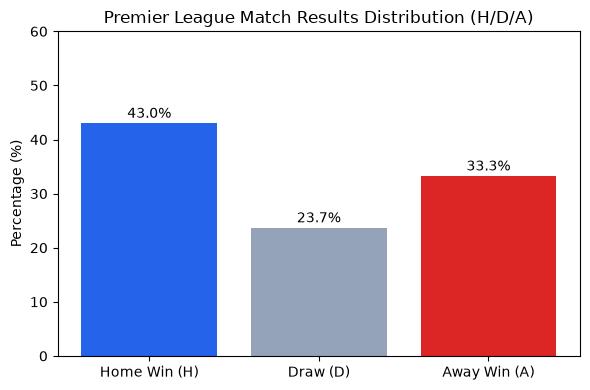

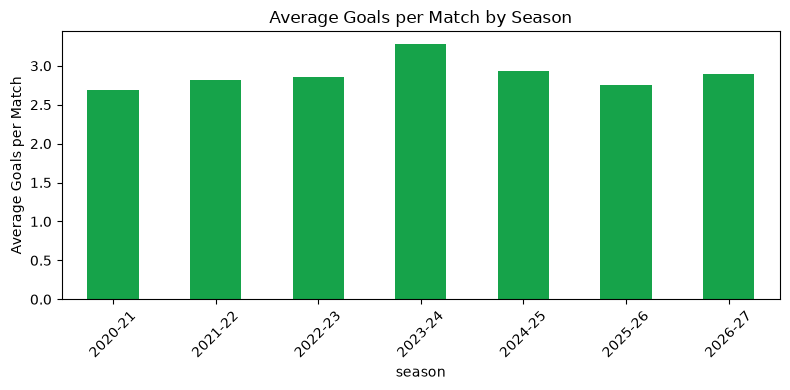

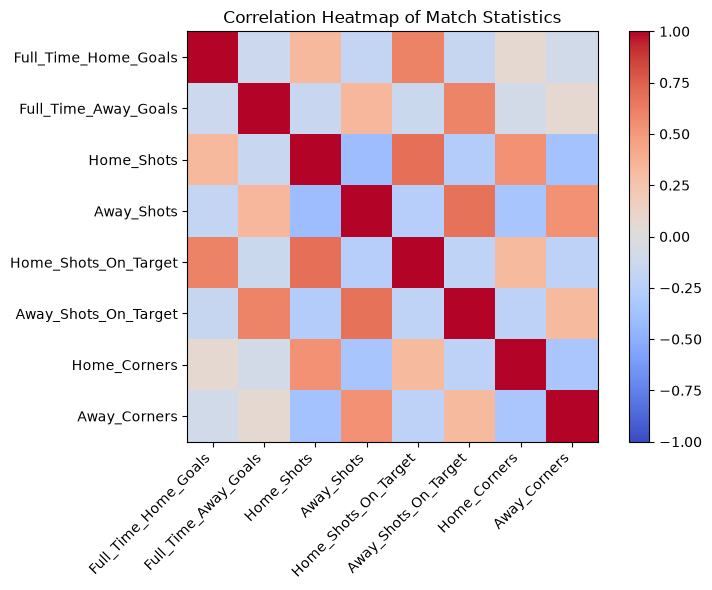

In [8]:
# 1. H/D/A Class Distribution
plt.figure(figsize=(6, 4))
labels = ["Home Win (H)", "Draw (D)", "Away Win (A)"]
values = [result_pct.get("H", 0), result_pct.get("D", 0), result_pct.get("A", 0)]
plt.bar(labels, values, color=["#2563eb", "#94a3b8", "#dc2626"])
plt.ylabel("Percentage (%)")
plt.title("Premier League Match Results Distribution (H/D/A)")
for i, v in enumerate(values):
    plt.text(i, v + 1, f"{v:.1f}%", ha="center")
plt.ylim(0, 60)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_hda_distribution.png", dpi=150)
plt.show()

# 2. Average Goals per Season
played_df["total_goals"] = played_df["Full_Time_Home_Goals"] + played_df["Full_Time_Away_Goals"]
goals_per_season = played_df.groupby("season")["total_goals"].mean()

plt.figure(figsize=(8, 4))
goals_per_season.plot(kind="bar", color="#16a34a")
plt.ylabel("Average Goals per Match")
plt.title("Average Goals per Match by Season")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_goals_per_season.png", dpi=150)
plt.show()

# 3. Correlation Heatmap of Numeric Match Stats
num_cols = [
    "Full_Time_Home_Goals", "Full_Time_Away_Goals",
    "Home_Shots", "Away_Shots",
    "Home_Shots_On_Target", "Away_Shots_On_Target",
    "Home_Corners", "Away_Corners",
]
corr = played_df[num_cols].corr()

plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(num_cols)), num_cols, rotation=45, ha="right")
plt.yticks(range(len(num_cols)), num_cols)
plt.title("Correlation Heatmap of Match Statistics")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_correlation_heatmap.png", dpi=150)
plt.show()

In [9]:
summary_lines = [
    "=== EXPLORATION SUMMARY (02_data_exploration.ipynb) ===",
    f"Total rows in all_matches_raw.csv : {len(df)}",
    f"Total played matches              : {total_played}",
    f"Duplicate rows                    : {df.duplicated().sum()}",
    f"Unique teams (Match CSVs)         : {len(match_teams)}",
    "",
    "--- BASELINES ---",
    f"Majority-class baseline (Always H): {result_pct.get('H', 0):.2f}%",
    f"Draw (D) frequency                : {result_pct.get('D', 0):.2f}%",
    f"Away Win (A) frequency            : {result_pct.get('A', 0):.2f}%",
    f"Average goals per match           : {avg_total_goals:.2f}",
    f"Home advantage (goals/match)      : +{avg_home_goals - avg_away_goals:.2f}",
]

SUMMARY_FILE.write_text("\n".join(summary_lines), encoding="utf-8")
print(f"Saved summary to: {SUMMARY_FILE}")

Saved summary to: ..\reports\exploration_summary.txt
